💡 Résistance nécessaire pour la LED : 130 Ω (Prendre valeur standard : 150 Ω ou 220 Ω)
⚡ U = 1.30 V | R = 220.0 Ω | I = 5.91 mA | Puissance P = 7.7 mW


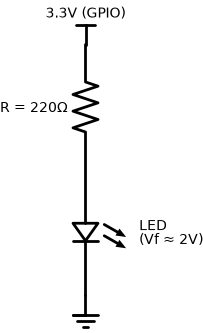

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

%config InlineBackend.figure_format = 'svg'

# 1. LOI D'OHM : U = R * I  |  PUISSANCE : P = U * I = R * I²
def loi_ohm(U=None, R=None, I=None):
    if U is None:
        U = R * I
    elif R is None:
        R = U / I
    elif I is None:
        I = U / R
    P = U * I
    print(f"⚡ U = {U:.2f} V | R = {R:.1f} Ω | I = {I*1000:.2f} mA | Puissance P = {P*1000:.1f} mW")

# Exemple : Calculer la résistance pour allumer une LED (Vf = 2.0V, I = 10mA) sur ESP32 (3.3V)
v_alim = 3.3
v_led = 2.0
i_led = 0.010  # 10 mA
r_led = (v_alim - v_led) / i_led
print(f"💡 Résistance nécessaire pour la LED : {r_led:.0f} Ω (Prendre valeur standard : 150 Ω ou 220 Ω)")
loi_ohm(U=(v_alim - v_led), R=220)

# Schéma associé
with schemdraw.Drawing() as d:
    d.config(fontsize=10, unit=2.5)
    d += elm.Vdd().label("3.3V (GPIO)")
    d += elm.Resistor().down().label("R = 220Ω")
    d += elm.LED().down().label("LED\n(Vf ≈ 2V)")
    d += elm.Ground()


➗ Entrée 5.0V avec R1=10000Ω et R2=20000Ω -> Sortie V_out = 3.33 V (Conso: 0.17 mA)


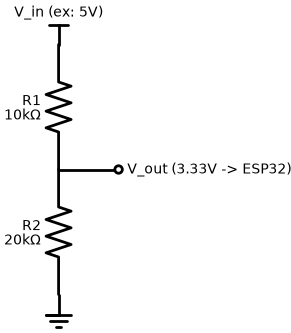

In [2]:
# Formule du pont diviseur : V_out = V_in * (R2 / (R1 + R2))
def pont_diviseur(v_in, r1, r2):
    v_out = v_in * (r2 / (r1 + r2))
    courant_ma = (v_in / (r1 + r2)) * 1000
    print(f"➗ Entrée {v_in}V avec R1={r1}Ω et R2={r2}Ω -> Sortie V_out = {v_out:.2f} V (Conso: {courant_ma:.2f} mA)")
    return v_out

# Exemple crucial : Adapter une sortie 5V (NE555 / Arduino) vers 3.3V (ESP32-C3)
pont_diviseur(v_in=5.0, r1=10000, r2=20000)

# Schéma du pont diviseur
with schemdraw.Drawing() as d:
    d.config(fontsize=10, unit=2.5)
    d += elm.Vdd().label("V_in (ex: 5V)")
    d += elm.Resistor().down().label("R1\n10kΩ")
    d.push()
    d += elm.Line().right(1.2)
    d += elm.Dot(open=True).label("V_out (3.33V -> ESP32)", loc="right")
    d.pop()
    d += elm.Resistor().down().label("R2\n20kΩ")
    d += elm.Ground()


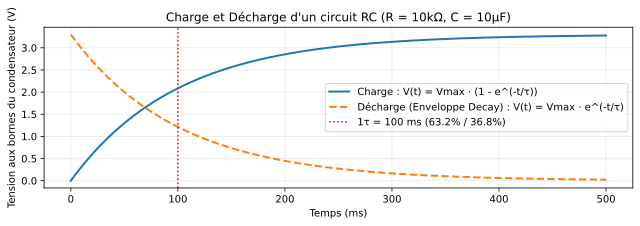

In [3]:
R = 10000.0   # 10 kOhm
C = 10e-6     # 10 uF
tau = R * C   # Constante de temps en secondes (0.1s = 100 ms)
V_max = 3.3

t = np.linspace(0, 5 * tau, 500)
v_charge = V_max * (1 - np.exp(-t / tau))
v_decharge = V_max * np.exp(-t / tau)

plt.figure(figsize=(9, 3.2))
plt.plot(t * 1000, v_charge, label="Charge : V(t) = Vmax · (1 - e^(-t/τ))", linewidth=2)
plt.plot(t * 1000, v_decharge, label="Décharge (Enveloppe Decay) : V(t) = Vmax · e^(-t/τ)", linewidth=2, linestyle="--")
plt.axvline(tau * 1000, color="red", linestyle=":", label=f"1τ = {tau*1000:.0f} ms (63.2% / 36.8%)")
plt.title(f"Charge et Décharge d'un circuit RC (R = {R/1000:.0f}kΩ, C = {C*1e6:.0f}µF)")
plt.xlabel("Temps (ms)")
plt.ylabel("Tension aux bornes du condensateur (V)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


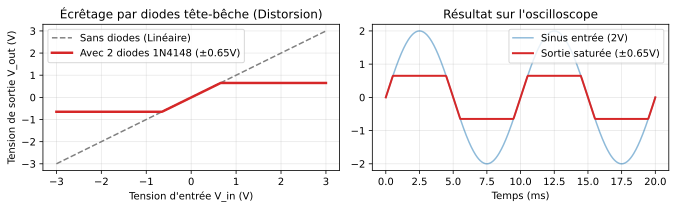

In [4]:
v_in = np.linspace(-3.0, 3.0, 500)
# Effet de 2 diodes 1N4148 montées tête-bêche (écrêteur de distorsion analogique)
v_seuil = 0.65
v_out_diodes = np.clip(v_in, -v_seuil, v_seuil)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3))

# Courbe de transfert
ax1.plot(v_in, v_in, linestyle="--", color="gray", label="Sans diodes (Linéaire)")
ax1.plot(v_in, v_out_diodes, color="#d62728", linewidth=2.5, label="Avec 2 diodes 1N4148 (±0.65V)")
ax1.set_title("Écrêtage par diodes tête-bêche (Distorsion)")
ax1.set_xlabel("Tension d'entrée V_in (V)")
ax1.set_ylabel("Tension de sortie V_out (V)")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Signal audio écrêté
t_s = np.linspace(0, 0.02, 500)
sin_in = 2.0 * np.sin(2 * np.pi * 100 * t_s)
ax2.plot(t_s * 1000, sin_in, alpha=0.5, label="Sinus entrée (2V)")
ax2.plot(t_s * 1000, np.clip(sin_in, -v_seuil, v_seuil), color="#d62728", linewidth=2, label="Sortie saturée (±0.65V)")
ax2.set_title("Résultat sur l'oscilloscope")
ax2.set_xlabel("Temps (ms)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


🔼 Ampli Non-Inverseur : Gain = 1 + (33000/10000) = x4.30 -> V_out = 2.15 V
🔽 Ampli Inverseur : Gain = -(22000/10000) = x-2.20 -> V_out = -1.10 V


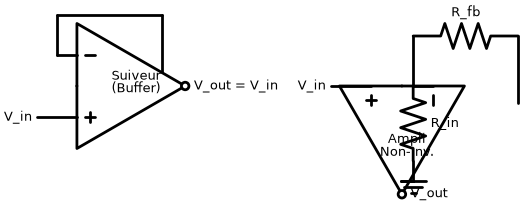

In [5]:
# Calculs des 3 montages fondamentaux d'un Ampli-Op (LM358)
def ampli_non_inverseur(v_in, r_in, r_feedback):
    gain = 1.0 + (r_feedback / r_in)
    print(f"🔼 Ampli Non-Inverseur : Gain = 1 + ({r_feedback}/{r_in}) = x{gain:.2f} -> V_out = {v_in * gain:.2f} V")

def ampli_inverseur(v_in, r_in, r_feedback):
    gain = -(r_feedback / r_in)
    print(f"🔽 Ampli Inverseur : Gain = -({r_feedback}/{r_in}) = x{gain:.2f} -> V_out = {v_in * gain:.2f} V")

ampli_non_inverseur(v_in=0.5, r_in=10000, r_feedback=33000)
ampli_inverseur(v_in=0.5, r_in=10000, r_feedback=22000)

# Schémas des 2 montages côte à côte
with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.2)

    # 1. Suiveur de tension (Buffer - Gain = 1, protège un signal fragile)
    op1 = elm.Opamp().label("Suiveur\n(Buffer)", loc="center")
    d += op1
    d += elm.Line().left(0.8).at(op1.in2).label("V_in", loc="left")
    d += elm.Line().left(0.4).at(op1.in1)
    d += elm.Line().up(0.8)
    d += elm.Line().right(2.1)
    d += elm.Line().down(1.15)
    d += elm.Dot(open=True).at(op1.out).label("V_out = V_in", loc="right")

    # 2. Amplificateur Non-Inverseur
    op2 = elm.Opamp().at((6.5, 0)).label("Ampli\nNon-Inv.", loc="center")
    d += op2
    d += elm.Line().left(0.8).at(op2.in2).label("V_in", loc="left")
    d += elm.Line().left(0.4).at(op2.in1)
    d.push()
    d += elm.Resistor().down(1.5).label("R_in", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += elm.Line().up(1.0)
    d += elm.Resistor().right(2.1).label("R_fb")
    d += elm.Line().down(1.35)
    d += elm.Dot(open=True).at(op2.out).label("V_out", loc="right")


⏱️ NE555 (RA=10000Ω, RB=105000Ω, C=100nF) -> Fréquence = 65.5 Hz | Rapport cyclique = 52.3%


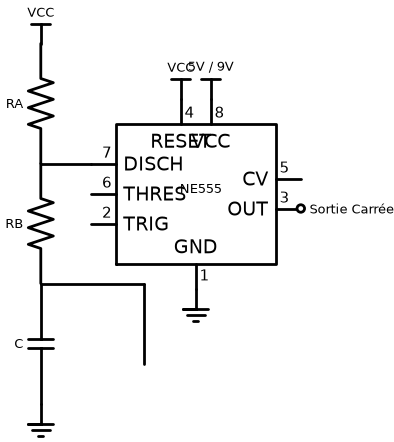

In [6]:
# Formule officielle du NE555 en mode Astable :
# f = 1.44 / ((RA + 2 * RB) * C)
# Rapport cyclique (Duty Cycle) = (RA + RB) / (RA + 2 * RB)

def calc_ne555(ra, rb, c):
    freq = 1.44 / ((ra + 2 * rb) * c)
    duty = ((ra + rb) / (ra + 2 * rb)) * 100
    print(f"⏱️ NE555 (RA={ra}Ω, RB={rb}Ω, C={c*1e9:.0f}nF) -> Fréquence = {freq:.1f} Hz | Rapport cyclique = {duty:.1f}%")
    return freq

# Exemple : Générer une note de basse autour de 65 Hz (Do2) avec un condensateur de 100nF
calc_ne555(ra=10000, rb=105000, c=100e-9)

# Schéma de câblage standard du NE555 Astable
with schemdraw.Drawing() as d:
    d.config(fontsize=9, unit=2.4)
    ic555 = elm.Ic(pins=[
        elm.IcPin(name="GND", side="bottom", pin="1"),
        elm.IcPin(name="TRIG", side="left", pin="2"),
        elm.IcPin(name="OUT", side="right", pin="3"),
        elm.IcPin(name="RESET", side="top", pin="4"),
        elm.IcPin(name="CV", side="right", pin="5"),
        elm.IcPin(name="THRES", side="left", pin="6"),
        elm.IcPin(name="DISCH", side="left", pin="7"),
        elm.IcPin(name="VCC", side="top", pin="8"),
    ], edgepadW=1.2, edgepadH=0.8).label("NE555", loc="center")
    d += ic555

    # Alimentation & Reset
    d += elm.Vdd().at(ic555.VCC).label("5V / 9V")
    d += elm.Vdd().at(ic555.RESET).label("VCC")
    d += elm.Ground().at(ic555.GND)

    # Réseau RA, RB, C
    d += elm.Line().left(1.0).at(ic555.DISCH)
    d.push()
    d += elm.Resistor().up().label("RA")
    d += elm.Vdd().label("VCC")
    d.pop()
    d += elm.Resistor().down().label("RB")
    d.push()
    d += elm.Line().right(1.0).to(ic555.THRES)
    d += elm.Line().down().to(ic555.TRIG)
    d.pop()
    d += elm.Capacitor().down().label("C")
    d += elm.Ground()

    # Sortie
    d += elm.Dot(open=True).at(ic555.OUT).label("Sortie Carrée", loc="right")
